<a href="https://colab.research.google.com/github/OJB-Quantum/MuMax3-How-To/blob/main/MuMax%20Notebooks/Heisenberg_Exchange_Spiral_MuMaxPlus.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
! echo "This machine runs" $(uname) "with" $(python --version) "and provides the following GPU/CUDA specs:"
! nvidia-smi

In [ ]:
!uv pip install mumaxplus matplotlib numpy

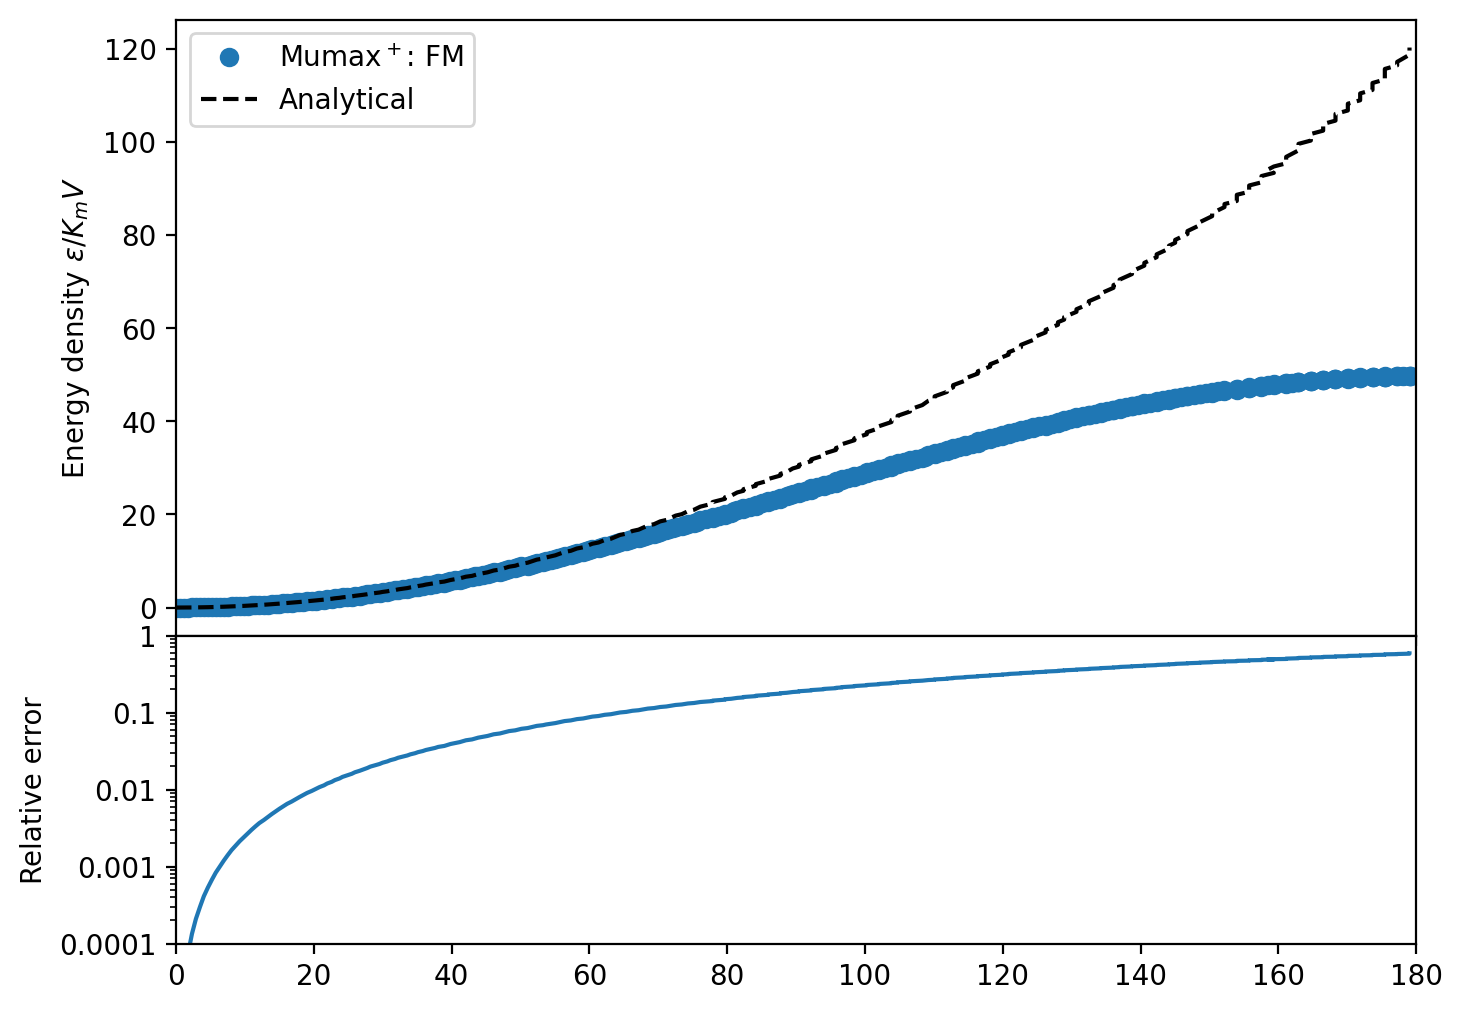

In [3]:
"""This script compares numerical and analytical exchange energy for spiral
magnetizations as a function of the angle between neighboring spins. This is a
recreation of figure 5 of the paper "The design and verification of MuMax3".
https://doi.org/10.1063/1.4899186 """

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np

from mumaxplus import Ferromagnet, Grid, World

plt.rcParams["figure.dpi"] = 200

def spiral(x, kx):
    mx = np.cos(kx * x)
    my = np.sin(kx * x)
    mz = np.zeros(shape=x.shape)
    return mx, my, mz


# --- Setup ---
msat = 800e3
aex = 5e-12
mu0 = 4 * np.pi * 1e-7

length, width, thickness = 100e-6, 1e-9, 1e-9
nx, ny, nz = int(length/1e-9), 1, 1
cx, cy, cz = length/nx, width/ny, thickness/nz
world = World(cellsize=(cx, cy, cz))

magnet = Ferromagnet(world, Grid((nx, ny, nz)))
magnet.msat = msat
magnet.aex = aex

V = length * width * thickness
Km = 0.5 * mu0 * msat**2  # magnetostatic energy density

# --- Find exchange energy per angle ---
angles, E_mumax, E_analytical = [], [], []
kx = 0
kx_step = 1e7
X, _, _ = magnet.magnetization.meshgrid  # for fast magnetization setting
magnet.magnetization = spiral(X, kx)
while (max_angle := magnet.max_angle.eval()) < (np.pi-.01):
    angles.append(max_angle * 180 / np.pi)
    E_mumax.append(magnet.exchange_energy.eval() / (Km * V))
    E_analytical.append(aex * kx**2 / Km)

    kx += kx_step
    magnet.magnetization = spiral(X, kx)


# --- Plotting ---
fig, (ax1, ax2) = plt.subplots(nrows=2, sharex=True, figsize=(8,6), gridspec_kw={'height_ratios': [2, 1]})
fig.subplots_adjust(hspace=0)

# energy per angle
ax1.plot(angles, E_mumax, 'o', label=r"Mumax$^+$: FM")
ax1.plot(angles, E_analytical, 'k--', label="Analytical")
ax1.set_xlim(0, 180)
ax1.set_xlabel(r"spin-spin angle (deg)")
ax1.set_ylabel(r"Energy density $\varepsilon / K_m V$")
ax1.legend()

# relative error
error = [np.abs(a-e)/a for (e,a) in zip(E_mumax[1:], E_analytical[1:])]
ax2.plot(angles[1:], error)
ax2.set_yscale("log")
ax2.set_ylabel("Relative error")
ax2.set_ylim(0.0001, 1)
ax2.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, pos:
            ('{{:.{:1d}f}}'.format(int(np.maximum(-np.log10(y),0)))).format(y)))

plt.show()